In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.notebook import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, transforms, datasets
from torch.optim.lr_scheduler import ReduceLROnPlateau

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

In [3]:
# Define transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(30),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [4]:
# Define dataset paths
train_path = "/kaggle/input/diagnosis-of-diabetic-retinopathy/train"
valid_path = "/kaggle/input/diagnosis-of-diabetic-retinopathy/valid"
test_path = "/kaggle/input/diagnosis-of-diabetic-retinopathy/test"

In [5]:
# Define datasets
train_dataset = datasets.ImageFolder(train_path, transform=transform)
valid_dataset = datasets.ImageFolder(valid_path, transform=transform)
test_dataset = datasets.ImageFolder(test_path, transform=transform)

In [6]:
# Define dataloaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [7]:
# Define visualization function
def visualize_samples(loader, class_labels):
    figure = plt.figure(figsize=(12, 12))
    cols, rows = 4, 4
    for i in range(1, cols * rows + 1):
        sample_idx = np.random.randint(len(loader.dataset))
        img, label = loader.dataset[sample_idx]
        figure.add_subplot(rows, cols, i)
        plt.title(class_labels[label])
        plt.axis("off")
        img_np = img.numpy().transpose((1, 2, 0))
        img_valid_range = np.clip(img_np, 0, 1)
        plt.imshow(img_valid_range)
    plt.show()

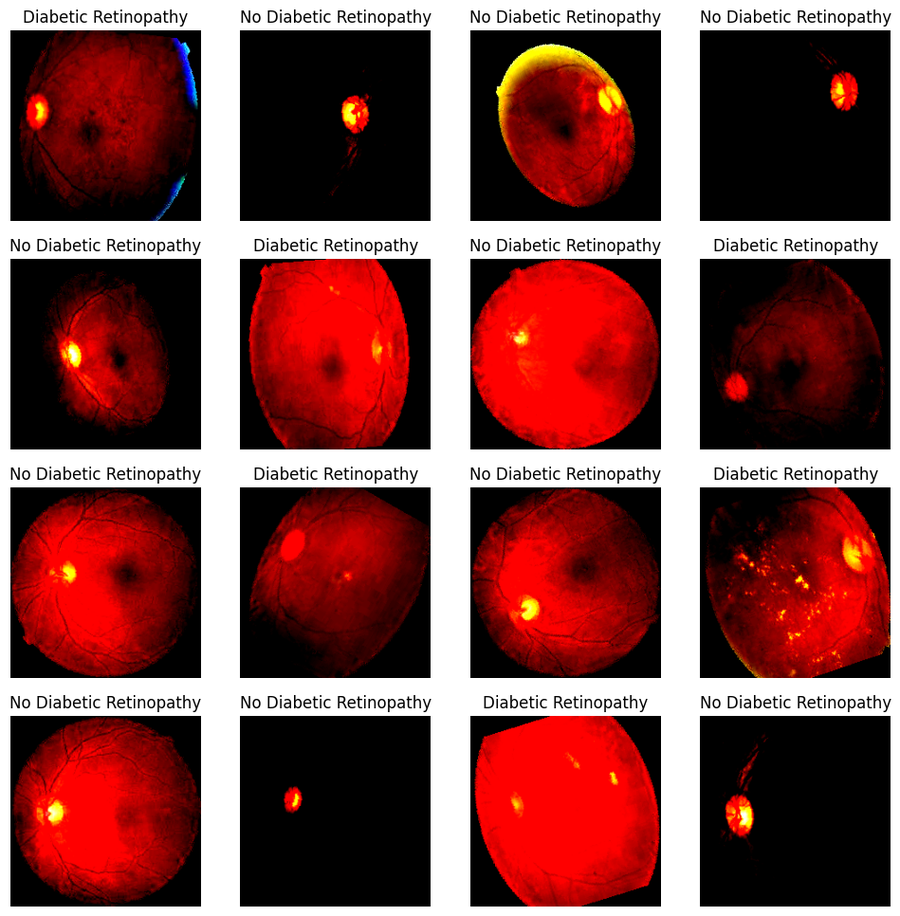

In [8]:
# Visualize some training samples
class_labels = {0: 'Diabetic Retinopathy', 1: 'No Diabetic Retinopathy'}
visualize_samples(train_loader, class_labels)

In [9]:
# Transfer learning using ResNet18
class TransferNet(nn.Module):
    def __init__(self, num_classes=2):
        super(TransferNet, self).__init__()
        resnet = models.resnet18(pretrained=True)
        # Remove the last fully connected layer
        self.features = nn.Sequential(*list(resnet.children())[:-1])
        # Add custom fully connected layer
        self.fc = nn.Linear(resnet.fc.in_features, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [10]:
# Create an instance of TransferNet
transfer_model = TransferNet()

/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s] 


In [11]:
# Move the model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
transfer_model = transfer_model.to(device)

In [12]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(transfer_model.parameters(), lr=1e-4)
lr_scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10, verbose=True)

In [13]:
# Training loop with transfer learning
def train_transfer_model(model, train_loader, valid_loader, criterion, optimizer, scheduler, num_epochs=20):
    for epoch in tqdm(range(num_epochs), desc="Epochs"):
        model.train()
        running_loss = 0.0
        for inputs, labels in tqdm(train_loader, desc="Training", leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        # Validation
        model.eval()
        val_loss = 0.0
        correct_preds = 0
        total_samples = 0
        with torch.no_grad():
            for inputs, labels in tqdm(valid_loader, desc="Validation", leave=False):
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, preds = torch.max(outputs, 1)
                correct_preds += torch.sum(preds == labels.data)
                total_samples += labels.size(0)

        avg_train_loss = running_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(valid_loader.dataset)
        accuracy = correct_preds.double() / total_samples

        scheduler.step(avg_val_loss)

        print(f'Epoch [{epoch + 1}/{num_epochs}], '
              f'Training Loss: {avg_train_loss:.4f}, '
              f'Validation Loss: {avg_val_loss:.4f}, '
              f'Accuracy: {accuracy:.4f}')

In [14]:
# Train the transfer model
train_transfer_model(transfer_model, train_loader, valid_loader, criterion, optimizer, lr_scheduler, num_epochs=10)

Epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/33 [00:00<?, ?it/s]

Validation:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [1/10], Training Loss: 0.0029, Validation Loss: 0.0014, Accuracy: 0.9661


Training:   0%|          | 0/33 [00:00<?, ?it/s]

Validation:   0%|          | 0/9 [00:00<?, ?it/s]

... (21 outputs left out)

Epoch [9/10], Training Loss: 0.0005, Validation Loss: 0.0012, Accuracy: 0.9774


Training:   0%|          | 0/33 [00:00<?, ?it/s]

Validation:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [10/10], Training Loss: 0.0006, Validation Loss: 0.0012, Accuracy: 0.9774


In [15]:
# Visualize confusion matrix
def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [16]:
# Evaluate the transfer model on the test set
def evaluate_transfer_model(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return all_labels, all_preds

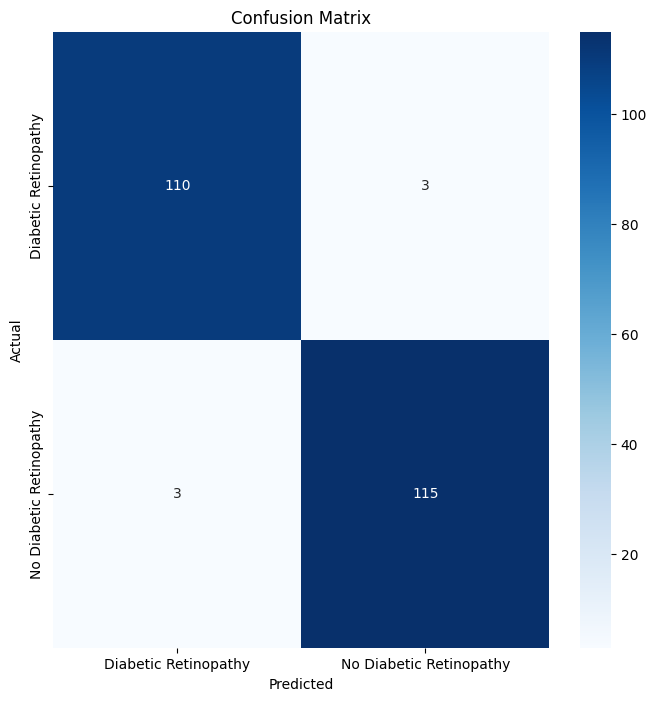

In [17]:
# Plot confusion matrix
class_labels = {0: 'Diabetic Retinopathy', 1: 'No Diabetic Retinopathy'}
y_true, y_pred = evaluate_transfer_model(transfer_model, test_loader)
plot_confusion_matrix(y_true, y_pred, classes=list(class_labels.values()))

In [18]:
# Save the transfer model
torch.save(transfer_model.state_dict(), "transfer_model.pth")

In [19]:
# Load the saved transfer model
loaded_transfer_model = TransferNet()
loaded_transfer_model.load_state_dict(torch.load("transfer_model.pth"))
loaded_transfer_model.to(device)

/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


TransferNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=

In [20]:
# Make predictions on a sample image
def predict_single_image(model, image_path, transform):
    model.eval()
    img = Image.open(image_path).convert('RGB')
    img = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img)
        probabilities = torch.softmax(output, dim=1)
        predicted_class = torch.argmax(probabilities, dim=1).item()
    return predicted_class, probabilities[0].cpu().numpy()

In [21]:
# Example prediction
image_path = "/kaggle/input/diagnosis-of-diabetic-retinopathy/test/DR/00cb6555d108_png.rf.29cca170969c6e9918ef9b9209abef8e.jpg"
predicted_class, probabilities = predict_single_image(loaded_transfer_model, image_path, transform)
class_name = class_labels[predicted_class]
print(f"Predicted class: {class_name}, Probabilities: {probabilities}")

Predicted class: Diabetic Retinopathy, Probabilities: [0.9664247  0.03357533]


In [22]:
def visualize_predicted_image(model, image_path, transform, class_labels):
    predicted_class, probabilities = predict_single_image(model, image_path, transform)
    class_name = class_labels[predicted_class]

    # Load and display the image
    img = Image.open(image_path).convert('RGB')
    plt.imshow(img)
    plt.title(f'Predicted Class: {class_name}\nProbabilities: {probabilities}')
    plt.axis('off')
    plt.show()

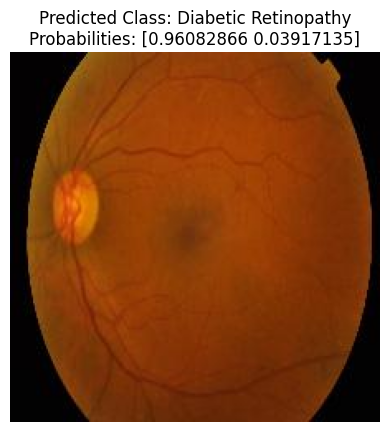

In [23]:
# Example usage:
image_path = "/kaggle/input/diagnosis-of-diabetic-retinopathy/test/DR/00cb6555d108_png.rf.29cca170969c6e9918ef9b9209abef8e.jpg"
visualize_predicted_image(loaded_transfer_model, image_path, transform, class_labels)